# Part 1: Ensemble methods

## 1. Datasets

We describe the 22 datasets of the course: number of examples `m`, dimension `d`, and share of the minority class. A dataset is flagged as imbalanced when its minority share is below 30%, since accuracy becomes misleading there (always predicting the majority class already scores above 70%).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent   # notebook is run from code/
sys.path[:0] = [str(ROOT), str(ROOT / "code")]

import numpy as np
import pandas as pd
import benchkit as bk

names = bk.REAL_SMALL + bk.REAL_LARGE
rows = []
for n in names:
    X, y = bk.real_dataset(n)
    p = np.mean(y == 1)
    rows.append(dict(dataset=n, m=X.shape[0], d=X.shape[1],
                     minority=round(min(p, 1 - p), 3)))

df = pd.DataFrame(rows)
IMB_THRESHOLD = 0.30  # below this minority share, accuracy is misleading
df["imbalanced"] = df["minority"] < IMB_THRESHOLD
df.sort_values("minority")

,dataset,m,d,minority,imbalanced
15,libras,360,90,0.067,True
18,satimage,6435,36,0.097,True
19,pageblocks,5473,10,0.102,True
13,yeast3,1484,8,0.110,True
21,bankmarketing,45211,51,0.117,True
20,abalone8,4177,10,0.136,True
14,segmentation,2310,19,0.143,True
9,vehicle,846,18,0.235,True
2,german,1000,24,0.300,False
12,newthyroid,215,5,0.302,False


### Selected datasets

We keep 18 datasets (7 imbalanced, 11 balanced), mixing small and large sizes. We drop `bankmarketing` (45k examples, too slow for our own implementations), and `bupa`, `balance`, `splice` (little information for their cost). `german` and `newthyroid` sit just above the 30% threshold, so they are only borderline balanced.

In [2]:
SELECTED = ["libras", "satimage", "pageblocks", "yeast3", "abalone8",
            "segmentation", "vehicle", "german", "newthyroid", "glass",
            "wine", "pima", "iono", "wdbc", "spambase", "heart",
            "australian", "sonar"]

sel = df[df["dataset"].isin(SELECTED)].sort_values("minority")
print(len(sel), "datasets,", sel["imbalanced"].sum(), "imbalanced")
sel

18 datasets, 7 imbalanced


,dataset,m,d,minority,imbalanced
15,libras,360,90,0.067,True
18,satimage,6435,36,0.097,True
19,pageblocks,5473,10,0.102,True
13,yeast3,1484,8,0.110,True
20,abalone8,4177,10,0.136,True
14,segmentation,2310,19,0.143,True
9,vehicle,846,18,0.235,True
2,german,1000,24,0.300,False
12,newthyroid,215,5,0.302,False
11,glass,214,9,0.327,False


## 2. Evaluation protocol

For each dataset we run repeated stratified hold-out (70% train / 30% test). Features are standardized with training statistics only. All models see the same splits. We report accuracy, balanced accuracy, F1 of the minority class and AUC.

In [3]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, roc_auc_score)

def get_scores(model, X):
    # continuous score needed for AUC
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]

def compute_metrics(model, Xte, yte, minority_label):
    pred = model.predict(Xte)
    try:
        auc = roc_auc_score(yte, get_scores(model, Xte))
    except Exception:
        auc = np.nan  # model without scores
    return dict(acc=accuracy_score(yte, pred),
                bacc=balanced_accuracy_score(yte, pred),
                f1_min=f1_score(yte, pred, pos_label=minority_label),
                auc=auc)
                
import time

def evaluate_model(model, X, y, n_rep=10, test_size=0.3, seed=0, noise=0.0):
    sss = StratifiedShuffleSplit(n_splits=n_rep, test_size=test_size,
                                 random_state=seed)
    out = []
    for r, (tr, te) in enumerate(sss.split(X, y)):
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xte = scaler.transform(X[tr]), scaler.transform(X[te])
        ytr = bk.flip_labels(y[tr], noise, seed + r) if noise > 0 else y[tr]
        minority = 1 if np.mean(y[tr] == 1) < 0.5 else -1
        t0 = time.perf_counter()
        mdl = clone(model).fit(Xtr, ytr)
        t_fit = time.perf_counter() - t0
        out.append(dict(compute_metrics(mdl, Xte, y[te], minority), t_fit=t_fit))
    return pd.DataFrame(out)

Quick check with a decision tree on wdbc

In [4]:
from sklearn.tree import DecisionTreeClassifier

Xw, yw = bk.real_dataset("wdbc")
res = evaluate_model(DecisionTreeClassifier(random_state=0), Xw, yw, n_rep=5)
res.mean().round(3)

acc       0.922
bacc      0.920
f1_min    0.898
auc       0.920
t_fit     0.006
dtype: float64

## 3. Bagging

Our own implementation: B decision trees, each trained on a bootstrap sample, combined by majority vote. The out-of-bag (OOB) error uses, for each training point, only the trees that did not see it.

In [5]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.tree import DecisionTreeClassifier

class MyBagging(BaseEstimator, ClassifierMixin):
    def __init__(self, n_estimators=100, max_depth=None, random_state=0):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.random_state = random_state

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n = len(y)
        self.classes_ = np.array([-1, 1])
        self.trees_ = []
        votes = np.zeros(n)   # sum of OOB votes per point
        counts = np.zeros(n)  # number of OOB votes per point
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, n)              # bootstrap sample
            oob = np.setdiff1d(np.arange(n), idx)    # points not drawn
            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=int(rng.integers(1 << 31))).fit(X[idx], y[idx])
            self.trees_.append(tree)
            if len(oob):
                votes[oob] += tree.predict(X[oob])
                counts[oob] += 1
        seen = counts > 0
        self.oob_error_ = np.mean(np.sign(votes[seen]) != y[seen])
        return self

    def decision_function(self, X):
        return np.mean([t.predict(X) for t in self.trees_], axis=0)

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

Check: bagging vs a single tree on wdbc, and OOB error vs test error

In [6]:
res_bag = evaluate_model(MyBagging(n_estimators=100), Xw, yw, n_rep=5)
print(res_bag.mean().round(3))

# OOB error vs test error on one split
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(Xw, yw, test_size=0.3,
                                      stratify=yw, random_state=0)
bag = MyBagging(n_estimators=100).fit(Xtr, ytr)
print("OOB error :", round(bag.oob_error_, 3))
print("Test error:", round(np.mean(bag.predict(Xte) != yte), 3))

acc       0.952
bacc      0.947
f1_min    0.935
auc       0.987
t_fit     0.528
dtype: float64
OOB error : 0.053
Test error: 0.064


## 4. AdaBoost

Our own implementation of discrete AdaBoost (labels in {-1, +1}). At each round a tree of fixed depth is trained on weighted examples; misclassified examples get a larger weight for the next round, and each tree votes with weight alpha.

In [7]:
class MyAdaBoost(BaseEstimator, ClassifierMixin):
    def __init__(self, n_estimators=100, max_depth=1, random_state=0):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.random_state = random_state

    def fit(self, X, y):
        n = len(y)
        self.classes_ = np.array([-1, 1])
        w = np.full(n, 1 / n)
        self.trees_, self.alphas_ = [], []
        for t in range(self.n_estimators):
            tree = DecisionTreeClassifier(
                max_depth=self.max_depth,
                random_state=self.random_state + t)
            tree.fit(X, y, sample_weight=w)
            pred = tree.predict(X)
            err = np.sum(w[pred != y])
            if err >= 0.5:                      # worse than chance: stop
                if not self.trees_:             # keep at least one tree
                    self.trees_.append(tree); self.alphas_.append(1.0)
                break
            err = max(err, 1e-10)               # avoid log(inf) if err = 0
            alpha = 0.5 * np.log((1 - err) / err)
            self.trees_.append(tree); self.alphas_.append(alpha)
            if err <= 1e-10:                    # perfect tree: stop
                break
            w *= np.exp(-alpha * y * pred)      # reweight
            w /= w.sum()
        return self

    def decision_function(self, X):
        return sum(a * t.predict(X) for a, t in zip(self.alphas_, self.trees_))

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

Check: AdaBoost with stumps vs deeper trees on wdbc.

In [8]:
for depth in [1, 3]:
    r = evaluate_model(MyAdaBoost(n_estimators=100, max_depth=depth),
                       Xw, yw, n_rep=5)
    print(f"depth={depth}")
    print(r.mean().round(3), "\n")

depth=1
acc       0.967
bacc      0.964
f1_min    0.956
auc       0.993
t_fit     0.255
dtype: float64 

depth=3
acc       0.970
bacc      0.964
f1_min    0.959
auc       0.995
t_fit     0.453
dtype: float64 



## 5. Stacking

Our own implementation: base models from different families produce out-of-fold probabilities (K-fold cross-validation on the training set), and a logistic regression meta-model is trained on them. At test time, base models refitted on the full training set feed the meta-model.

In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

def default_base_models():
    return [DecisionTreeClassifier(max_depth=5, random_state=0),
            LogisticRegression(max_iter=1000),
            KNeighborsClassifier(n_neighbors=7)]

class MyStacking(BaseEstimator, ClassifierMixin):
    def __init__(self, base_models=None, n_folds=5, random_state=0):
        self.base_models = base_models
        self.n_folds = n_folds
        self.random_state = random_state

    def _meta_features(self, models, X):
        # probability of class +1 from each base model
        return np.column_stack([m.predict_proba(X)[:, 1] for m in models])

    def fit(self, X, y):
        self.classes_ = np.array([-1, 1])
        base = self.base_models or default_base_models()
        skf = StratifiedKFold(self.n_folds, shuffle=True,
                              random_state=self.random_state)
        Z = np.zeros((len(y), len(base)))   # out-of-fold predictions
        for tr, va in skf.split(X, y):
            for j, m in enumerate(base):
                fold_model = clone(m).fit(X[tr], y[tr])
                Z[va, j] = fold_model.predict_proba(X[va])[:, 1]
        self.fitted_ = [clone(m).fit(X, y) for m in base]   # refit on all data
        self.meta_ = LogisticRegression(max_iter=1000).fit(Z, y)
        return self

    def decision_function(self, X):
        return self.meta_.decision_function(self._meta_features(self.fitted_, X))

    def predict(self, X):
        return self.meta_.predict(self._meta_features(self.fitted_, X))

Check: stacking vs its best member on wdbc

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

r_stack = evaluate_model(MyStacking(), Xw, yw, n_rep=5)
print("Stacking\n", r_stack.mean().round(3), "\n")
for name, m in [("Logistic regression", LogisticRegression(max_iter=1000)),
                ("kNN (k=7)", KNeighborsClassifier(n_neighbors=7))]:
    print(name, "\n", evaluate_model(m, Xw, yw, n_rep=5).mean().round(3), "\n")

Stacking
 acc       0.967
bacc      0.963
f1_min    0.956
auc       0.993
t_fit     0.151
dtype: float64 

Logistic regression 
 acc       0.974
bacc      0.971
f1_min    0.965
auc       0.994
t_fit     0.013
dtype: float64 

kNN (k=7) 
 acc       0.952
bacc      0.945
f1_min    0.935
auc       0.988
t_fit     0.001
dtype: float64 



## 6. Validation against scikit-learn

Each implementation is compared with its scikit-learn counterpart, with the same hyperparameters and the same splits. Metrics should be close; for bagging we also compare the OOB errors.

In [11]:
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier,
                              StackingClassifier)

def sk_stacking():
    names = ["tree", "lr", "knn"]
    return StackingClassifier(list(zip(names, default_base_models())),
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=5)

pairs = {
    "Bagging":  (MyBagging(n_estimators=100),
                 BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                   random_state=0)),
    "AdaBoost": (MyAdaBoost(n_estimators=100, max_depth=1),
                 AdaBoostClassifier(DecisionTreeClassifier(max_depth=1),
                                    n_estimators=100,
                                    random_state=0)),
    "Stacking": (MyStacking(), sk_stacking()),
}

rows = []
for name, (mine, ref) in pairs.items():
    for label, mdl in [("ours", mine), ("sklearn", ref)]:
        r = evaluate_model(mdl, Xw, yw, n_rep=5).mean()
        rows.append(dict(model=name, impl=label, **r.round(3)))
pd.DataFrame(rows)

,model,impl,acc,bacc,f1_min,auc,t_fit
0,Bagging,ours,0.952,0.947,0.935,0.987,0.517
1,Bagging,sklearn,0.953,0.948,0.937,0.987,0.440
2,AdaBoost,ours,0.967,0.964,0.956,0.993,0.248
3,AdaBoost,sklearn,0.967,0.964,0.956,0.993,0.278
4,Stacking,ours,0.967,0.963,0.956,0.993,0.126
5,Stacking,sklearn,0.967,0.964,0.956,0.993,0.139


OOB error: our bagging vs sklearn, on one split.

In [12]:
ours = MyBagging(n_estimators=100).fit(Xtr, ytr)
ref = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                        oob_score=True, random_state=0).fit(Xtr, ytr)
print("OOB error ours   :", round(ours.oob_error_, 3))
print("OOB error sklearn:", round(1 - ref.oob_score_, 3))

OOB error ours   : 0.053
OOB error sklearn: 0.045


## 7. Full benchmark

All models are evaluated on the 18 selected datasets with 10 repeated stratified hold-out splits. Results are saved to `results/benchmark.csv` so the experiment is run only once.

In [13]:
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier)

MODELS = {
    "Tree": DecisionTreeClassifier(random_state=0),
    "LogReg": LogisticRegression(max_iter=1000),
    "kNN": KNeighborsClassifier(n_neighbors=7),
    "Bagging": MyBagging(n_estimators=100),
    "RF": RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    "AdaBoost-d1": MyAdaBoost(n_estimators=100, max_depth=1),
    "AdaBoost-d3": MyAdaBoost(n_estimators=100, max_depth=3),
    "GBM": GradientBoostingClassifier(random_state=0),
    "HistGBM": HistGradientBoostingClassifier(random_state=0),
    "Stacking": MyStacking(),
}
METRICS = ["acc", "bacc", "f1_min", "auc"]
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
N_REP = 10   # use 3 for a quick test run 10 after

def run_benchmark(datasets, models, n_rep):
    rows = []
    for d in datasets:
        X, y = bk.real_dataset(d)
        for name, mdl in models.items():
            r = evaluate_model(mdl, X, y, n_rep=n_rep).mean()
            rows.append(dict(dataset=d, model=name, **r.to_dict()))
        print("done:", d)
    return pd.DataFrame(rows)

path = RESULTS / "benchmark.csv"
if path.exists():
    res = pd.read_csv(path)
else:
    res = run_benchmark(SELECTED, MODELS, N_REP)
    res.to_csv(path, index=False)
res.head()

done: libras
done: satimage
done: pageblocks
done: yeast3
done: abalone8
done: segmentation
done: vehicle
done: german
done: newthyroid
done: glass
done: wine
done: pima
done: iono
done: wdbc
done: spambase
done: heart
done: australian
done: sonar


,dataset,model,acc,bacc,f1_min,auc,t_fit
0,libras,Tree,0.945370,0.758062,0.560269,0.758062,0.011732
1,libras,LogReg,0.984259,0.878571,0.858625,0.975672,0.012213
2,libras,kNN,0.960185,0.712801,0.552685,0.971358,0.000742
3,libras,Bagging,0.956481,0.684229,0.504266,0.935644,0.956924
4,libras,RF,0.962037,0.707143,0.567121,0.989321,0.393008


## 8. Average ranks and effect of the metric

Models are ranked on each dataset (rank 1 = best) and ranks are averaged, separately on balanced and imbalanced datasets, for each metric.

In [14]:
imb = set(df.loc[df["imbalanced"], "dataset"])
res["group"] = np.where(res["dataset"].isin(imb), "imbalanced", "balanced")

def avg_ranks(res, metric, group):
    p = res[res["group"] == group].pivot(index="dataset", columns="model", values=metric)
    return p.rank(axis=1, ascending=False).mean()

ranks = pd.DataFrame({(g, m): avg_ranks(res, m, g)
                      for g in ["balanced", "imbalanced"] for m in METRICS})
ranks.round(1).sort_values(("imbalanced", "bacc"))

balanced                  imbalanced                  
                 acc bacc f1_min  auc        acc bacc f1_min   auc
model                                                             
HistGBM          4.4  4.1    4.1  4.4        3.6  2.6    2.7   2.7
AdaBoost-d3      5.2  4.7    4.5  5.1        4.0  3.3    4.0   3.3
Bagging          6.0  5.3    5.5  6.2        6.1  5.1    5.6   6.3
RF               3.2  3.6    3.7  2.9        4.2  5.3    4.7   3.0
GBM              4.8  4.5    4.5  5.0        5.2  5.4    5.3   5.0
Stacking         4.4  5.5    5.5  4.4        4.1  6.1    5.1   4.1
kNN              7.6  7.6    7.6  7.3        6.9  6.4    6.1   8.0
Tree             9.5  9.1    9.2  9.9        8.9  6.6    7.3  10.0
AdaBoost-d1      4.8  4.9    4.8  5.1        5.5  6.8    6.9   6.3
LogReg           5.1  5.6    5.6  4.8        6.4  7.4    7.3   6.3

Accuracy overestimates performance on imbalanced datasets: gap between accuracy and balanced accuracy, averaged over the imbalanced datasets.

In [15]:
sub = res[res["group"] == "imbalanced"]
gap = (sub.pivot(index="dataset", columns="model", values="acc")
       - sub.pivot(index="dataset", columns="model", values="bacc")).mean()
gap.sort_values(ascending=False).round(3)

model
LogReg         0.181
kNN            0.141
RF             0.138
Bagging        0.135
AdaBoost-d1    0.135
Stacking       0.132
GBM            0.131
AdaBoost-d3    0.117
Tree           0.115
HistGBM        0.110
dtype: float64

## 9. Statistical comparison

Friedman test over the 18 datasets, followed by the Nemenyi critical distance (Demsar, 2006). Two models whose average ranks differ by less than the critical distance are not significantly different.

Friedman chi2 = 35.9, p = 4.1e-05, CD = 3.19


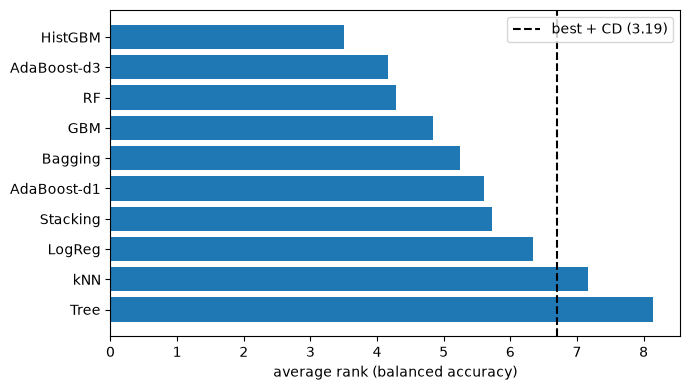

In [16]:
from scipy.stats import friedmanchisquare
import matplotlib.pyplot as plt

Q_NEMENYI = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850,
             7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}

def friedman_nemenyi(res, metric):
    p = res.pivot(index="dataset", columns="model", values=metric)
    N, k = p.shape
    stat, pval = friedmanchisquare(*[p[c] for c in p.columns])
    ranks = p.rank(axis=1, ascending=False).mean().sort_values()
    cd = Q_NEMENYI[k] * np.sqrt(k * (k + 1) / (6 * N))
    return stat, pval, ranks, cd

stat, pval, ranks_bacc, cd = friedman_nemenyi(res, "bacc")
print(f"Friedman chi2 = {stat:.1f}, p = {pval:.2g}, CD = {cd:.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(ranks_bacc.index[::-1], ranks_bacc.values[::-1])
ax.axvline(ranks_bacc.iloc[0] + cd, ls="--", c="k", label=f"best + CD ({cd:.2f})")
ax.set_xlabel("average rank (balanced accuracy)"); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS / "ranks_bacc.png", dpi=150); plt.show()

## 10. Gain over a single tree and over another model family

Mean gain in balanced accuracy over the single tree and over logistic regression, with the number of datasets where each model wins or loses.

In [17]:
def gains(res, metric, ref):
    p = res.pivot(index="dataset", columns="model", values=metric)
    d = p.sub(p[ref], axis=0).drop(columns=ref)
    return pd.DataFrame({"mean_gain": d.mean(), "wins": (d > 0).sum(),
                         "losses": (d < 0).sum()}).sort_values("mean_gain", ascending=False)

print("vs single tree"); display(gains(res, "bacc", "Tree").round(3))
print("vs logistic regression"); display(gains(res, "bacc", "LogReg").round(3))

vs single tree


,mean_gain,wins,losses
model,,,
HistGBM,0.051,17,1
AdaBoost-d3,0.046,17,1
RF,0.041,16,2
GBM,0.038,16,2
AdaBoost-d1,0.035,14,4
Bagging,0.034,16,2
Stacking,0.033,13,4
kNN,0.008,9,9
LogReg,-0.001,10,8


vs logistic regression


,mean_gain,wins,losses
model,,,
HistGBM,0.052,11,7
AdaBoost-d3,0.047,12,6
RF,0.042,12,6
GBM,0.039,12,6
AdaBoost-d1,0.037,10,8
Bagging,0.035,12,6
Stacking,0.034,11,7
kNN,0.009,8,10
Tree,0.001,8,10


## 11. Bagging or boosting?

First, dataset by dataset: where does boosting beat bagging, as a function of size, dimension and imbalance?

In [18]:
p = res.pivot(index="dataset", columns="model", values="bacc")
cmp = df.set_index("dataset")[["m", "d", "minority"]].join(
    pd.DataFrame({"Bagging": p["Bagging"], "RF": p["RF"],
                  "AdaBoost-d1": p["AdaBoost-d1"], "GBM": p["GBM"]}))
cmp["boost - bag"] = cmp["AdaBoost-d1"] - cmp["Bagging"]
cmp.loc[SELECTED].sort_values("boost - bag").round(3)

,m,d,minority,Bagging,RF,AdaBoost-d1,GBM,boost - bag
dataset,,,,,,,,
segmentation,2310,19,0.143,0.941,0.948,0.884,0.945,-0.058
pageblocks,5473,10,0.102,0.927,0.926,0.875,0.918,-0.052
abalone8,4177,10,0.136,0.546,0.534,0.500,0.516,-0.046
satimage,6435,36,0.097,0.755,0.751,0.727,0.754,-0.028
glass,214,9,0.327,0.817,0.827,0.805,0.822,-0.012
australian,690,14,0.445,0.863,0.868,0.853,0.864,-0.010
spambase,4597,57,0.394,0.937,0.946,0.930,0.939,-0.007
german,1000,24,0.300,0.681,0.655,0.676,0.678,-0.005
iono,351,34,0.359,0.901,0.922,0.897,0.908,-0.004


Robustness to label noise: training labels are flipped with probability eta, test labels stay clean (5 splits).


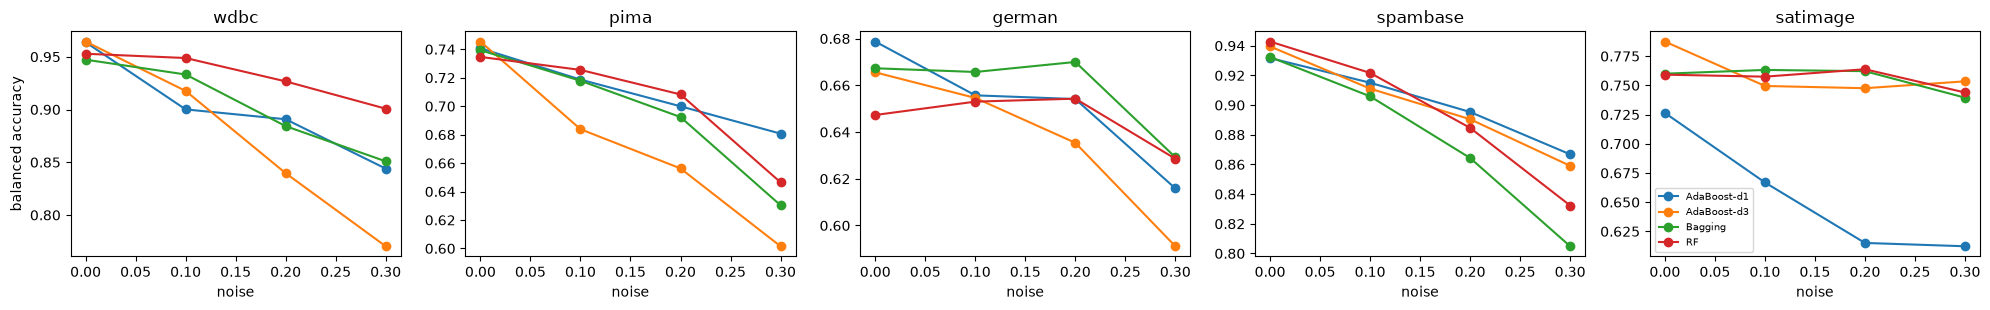

In [19]:
NOISE_DS = ["wdbc", "pima", "german", "spambase", "satimage"]
NOISE_MODELS = ["Bagging", "RF", "AdaBoost-d1", "AdaBoost-d3"]
rows = []
for d in NOISE_DS:
    X, y = bk.real_dataset(d)
    for eta in [0.0, 0.1, 0.2, 0.3]:
        for name in NOISE_MODELS:
            r = evaluate_model(MODELS[name], X, y, n_rep=5, noise=eta).mean()
            rows.append(dict(dataset=d, noise=eta, model=name, bacc=r["bacc"]))
noise_df = pd.DataFrame(rows)
noise_df.to_csv(RESULTS / "noise.csv", index=False)

fig, axes = plt.subplots(1, len(NOISE_DS), figsize=(4 * len(NOISE_DS), 3.2), sharey=False)
for ax, d in zip(axes, NOISE_DS):
    noise_df[noise_df.dataset == d].pivot(index="noise", columns="model",
                                          values="bacc").plot(ax=ax, marker="o", legend=False)
    ax.set_title(d)
axes[0].set_ylabel("balanced accuracy"); axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(RESULTS / "noise.png", dpi=150); plt.show()

Effect of the depth of the base trees (balanced accuracy, 5 splits).

In [20]:
DEPTH_DS = ["wdbc", "pima", "german", "vehicle"]
rows = []
for d in DEPTH_DS:
    X, y = bk.real_dataset(d)
    for depth in [1, 2, 3, 5]:
        r = evaluate_model(MyAdaBoost(100, depth), X, y, n_rep=5).mean()
        rows.append(dict(dataset=d, model="AdaBoost", depth=depth, bacc=r["bacc"]))
    for depth in [1, 3, 5, None]:
        r = evaluate_model(MyBagging(100, depth), X, y, n_rep=5).mean()
        rows.append(dict(dataset=d, model="Bagging", depth=str(depth), bacc=r["bacc"]))
depth_df = pd.DataFrame(rows)
depth_df.pivot_table(index=["model", "depth"], columns="dataset", values="bacc").round(3)

dataset         german   pima  vehicle   wdbc
model    depth                               
AdaBoost 1       0.679  0.741    0.939  0.964
         2       0.676  0.732    0.951  0.964
         3       0.666  0.745    0.957  0.964
         5       0.670  0.725    0.957  0.943
Bagging  1       0.500  0.695    0.500  0.916
         3       0.610  0.721    0.902  0.945
         5       0.635  0.726    0.909  0.946
         None    0.667  0.739    0.926  0.947

## 12. Stacking: gain and cost

Does stacking beat the best of its three members (tree, logistic regression, kNN)? Cost is measured by training time.

In [21]:
members = ["Tree", "LogReg", "kNN"]
pb = res.pivot(index="dataset", columns="model", values="bacc")
pt = res.pivot(index="dataset", columns="model", values="t_fit")
st = pd.DataFrame({"stacking": pb["Stacking"],
                   "best_member": pb[members].max(axis=1),
                   "best_name": pb[members].idxmax(axis=1)})
st["gain"] = st["stacking"] - st["best_member"]
st["time_ratio"] = pt["Stacking"] / pt[members].sum(axis=1)
display(st.round(3))
print("stacking wins on", (st["gain"] > 0).sum(), "of", len(st), "datasets")

pt.median().sort_values().round(3).rename("median fit time (s)")

,stacking,best_member,best_name,gain,time_ratio
dataset,,,,,
abalone8,0.513,0.563,Tree,-0.050,5.665
australian,0.869,0.862,LogReg,0.007,7.632
german,0.666,0.698,LogReg,-0.032,10.816
glass,0.752,0.766,Tree,-0.014,6.299
heart,0.812,0.829,LogReg,-0.016,7.025
iono,0.874,0.844,Tree,0.030,6.454
libras,0.821,0.879,LogReg,-0.057,6.868
newthyroid,0.904,0.904,Tree,0.000,6.035
pageblocks,0.893,0.900,Tree,-0.007,5.085


stacking wins on 4 of 18 datasets


model
kNN            0.001
Tree           0.005
LogReg         0.010
Stacking       0.123
HistGBM        0.185
AdaBoost-d1    0.220
GBM            0.263
AdaBoost-d3    0.350
RF             0.415
Bagging        0.506
Name: median fit time (s), dtype: float64